# V3 material classification: completed evidence review

**Locked primary:** frozen DINOv2 multiscale + ConvNeXt features with a saved
scaler/logistic head. Its fresh accuracy is **80.1587%**, macro-F1 **0.7952**,
with a source-group bootstrap accuracy interval of **66.03â€“93.65%**.
Fine-tuned DINOv2 reaches **86.8254%**, macro-F1 **0.8631**, with an interval of
**76.98â€“95.87%**, as an **exploratory comparison**. It does not replace the primary.

This executable notebook reads committed evidence only. It never loads model
weights, renders images, trains, scores images, or fits calibration. Recomputed
metrics are checks on saved predictions. Saved bootstrap intervals are read,
not regenerated. All paths resolve from a repository root, without machine paths.
Historical progress notes in `reports/V3_STATE.md` are superseded by the completed
execution summaries for final results. The last cell records successful checks.

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib, json, io, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Image, Markdown

ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "metadata/v3/manifest.csv").is_file()
    ),
    None,
)
assert ROOT is not None, "Run from the repository root or notebooks directory"
BASE = "reports/results/v3/"
names = ["frozen_selected", "frozen_control", "resnet_fixed", "dinov2_finetuned"]
labels = dict(
    zip(
        names,
        [
            "Frozen selected (PRIMARY)",
            "Frozen ConvNeXt control",
            "ResNet fixed baseline",
            "DINOv2 fine-tuned (exploratory)",
        ],
    )
)
pd.set_option("display.max_colwidth", 55)
pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


def read_json(name):
    return json.loads((ROOT / BASE / name).read_text(encoding="utf-8"))


def read_csv(name):
    return pd.read_csv(ROOT / BASE / name)


def table(rows, digits=4):
    frame = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    display(frame.round(digits))


def saved_plot(name, width=900):
    # Embed a resized copy of the saved figure; the source file is unchanged.
    with PILImage.open(ROOT / BASE / name) as im:
        im = im.convert("RGB")
        im.thumbnail((width, 950))
        buf = io.BytesIO()
        im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue()))


lock = read_json("final_model_lock.json")
choice = read_json("model_choice.json")
final = read_json("final_execution_summary.json")
neural = read_json("neural_execution_summary.json")
classes = lock["class_order"]
print("Evidence-only CPU analysis; Python", platform.python_version())
print(
    "Notebook packages:", {n: version(n) for n in ["nbformat", "nbclient", "ipykernel"]}
)

Evidence-only CPU analysis; Python 3.13.5
Notebook packages: {'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


## Evidence identity and integrity

The following SHA-256 inventory pins every file consumed by this notebook.
Text digests normalize **CRLF to LF only** to survive Git checkout settings;
PNG digests are exact bytes. Original execution hashes are checked separately
against exact or newline-equivalent text bytes. Hashes establish consistency
with saved records, not independent proof of provenance. Raw images and model
weights are deliberately unnecessary for this analysis.

In [2]:
EXPECTED_SHA256 = {
    "metadata/v3/manifest.csv": "8ffafa1709c36d78fb7215535c33ea04ee42ffc08f71719b5ad941ba58d4501f",
    "metadata/v3_holdout/classification_manifest.csv": "15edb1e32ceaaf190470a45c923270ba93fa83b4eb1a34c29fa7ed06abdda4f9",
    "reports/results/v3/benchmarks/dinov2_finetuned/benchmark.json": "2de8bfc89bd8814f0d840fd912540cce4e97cd6b15c95f7ecaad847d75bf5439",
    "reports/results/v3/benchmarks/frozen_control/benchmark.json": "95dd3a4c9c673fc3bbb6d6eee011468808d087923419e79c1c97e1ec5990f469",
    "reports/results/v3/benchmarks/frozen_selected/benchmark.json": "a73eb0f4635a4f3434695f18089456e1236cd5b612b1220bb8261ba6d2823b54",
    "reports/results/v3/benchmarks/resnet_fixed/benchmark.json": "eb99aeac787ffe20d0bf9d8dcf9b584648656be6a5a196a830b8fd4564f86d70",
    "reports/results/v3/exploratory_robustness_amendment.json": "ba911be5bb210f1c6142069d77b765820292b8971415e7e44658aa907e588ea5",
    "reports/results/v3/extraction_summary.json": "b73c7a0292cb46d902c761d42bf080cbf7dfb8f9d5bf483da4a7f85f6a2a2a15",
    "reports/results/v3/final_execution_summary.json": "801e15d118170948ca181b1a42d0af8eec3997cfda14921cf88a50bcc8b4c2f5",
    "reports/results/v3/final_model_lock.json": "4a5c02f5d9fc6c38b5de227db5520c89a29c0d75da94b689abc4e9f41f88d0bf",
    "reports/results/v3/finetune_development/all_development/progress.json": "d9b41030190313e06e3a72b51c8dd557ba95b32e4bc6caafda141553b401bb18",
    "reports/results/v3/finetune_development/lr_1e-05_fold_0/progress.json": "a39bcd935c501170a0dde1fb9e16ece2bf755541ab8faf4d19171cd304c9d1c8",
    "reports/results/v3/finetune_development/lr_1e-05_fold_1/progress.json": "cb4dd3397750b37d221f6130945f5777be835ed9dcaaf8d5695371fef04a7b3d",
    "reports/results/v3/finetune_development/lr_1e-05_fold_2/progress.json": "d314a3389729f0e4810963ac6ee3c9ac4e0ece4be7aa984d5020cc42050953ca",
    "reports/results/v3/finetune_development/lr_3e-06_fold_0/progress.json": "460309086e41ac99cdaa0e9e691f546f82c668e92630e29189dae9e16cf6bbdf",
    "reports/results/v3/finetune_development/lr_3e-06_fold_1/progress.json": "dc6cb822a4ac6b2fdf2c3aaf623a677c303911345614d177e1c615d672e02896",
    "reports/results/v3/finetune_development/lr_3e-06_fold_2/progress.json": "f8a3108fb6aec63034bae00d11328907d561af1738fecc11378a095559c766d5",
    "reports/results/v3/finetune_development/selection.json": "920763f9ae280bebe27a31eb57b96c108e81cfaa98b8e64229aec5ae3c790845",
    "reports/results/v3/fresh/dinov2_finetuned/evaluation.json": "d84500c1ca5938f465d92fdb2d03ea925c5b614ee6d5bfaa45987f0ad7ec7e76",
    "reports/results/v3/fresh/dinov2_finetuned/figures/calibration.png": "a4555891b5e3cdb028dd2a3ae3c76c3e035daafe86b9e1ae20b49b2d32812173",
    "reports/results/v3/fresh/dinov2_finetuned/figures/image_confusion.png": "8158303db21a2b1e4b781e1bcde04e2892903b3b7d62f7be0c3c23604db7acf7",
    "reports/results/v3/fresh/dinov2_finetuned/prediction_run.json": "091264056332e6bd513f583beee6e7d45f136a3b14718d9111ca8fe81b3da73a",
    "reports/results/v3/fresh/dinov2_finetuned/predictions.csv": "4828bbc01a4071809c37c2e8fec3d4260d48a356bcc4a2335b60fb7099a305bd",
    "reports/results/v3/fresh/frozen_control/evaluation.json": "f2e56cb8f1c861fb13bb4f4e2e02656ca0ad5e5876541ae6f100d653bbc495f2",
    "reports/results/v3/fresh/frozen_control/figures/calibration.png": "8fb41e690b1ffe4fae0f903e7954a8f2aee14d8352f855989ccbd5711bc7452c",
    "reports/results/v3/fresh/frozen_control/figures/image_confusion.png": "013940bb0b2ded067e187c35a63c8900c1d5244def426ddf481de9810b8e94e3",
    "reports/results/v3/fresh/frozen_control/prediction_run.json": "556559a8a935f198453fd5da8b92010fdee7a40cfcc4525174127a37dc88a9f2",
    "reports/results/v3/fresh/frozen_control/predictions.csv": "7fada3a3bacd8d1a75680a96a06d97889e55765019363b1ca44db2bedd2e10ad",
    "reports/results/v3/fresh/frozen_selected/evaluation.json": "87a8937958502f217d8a3d157c34b4079aa0ed3ca0b5e627b94c5f2b11e611ba",
    "reports/results/v3/fresh/frozen_selected/figures/calibration.png": "6868b05b06c32be3fcc36f8ff16a02e0492f275328735ffde14f8bd011d509b7",
    "reports/results/v3/fresh/frozen_selected/figures/image_confusion.png": "c99b1bebd45102ac0f68736ccd7b8ce4dc41fa0a59fdf861a15204bf96d0c5d1",
    "reports/results/v3/fresh/frozen_selected/prediction_run.json": "d3b2e556db91840f42d5f819357f7e8b51d2b895b5b0a24ded8e71f29e45dd2e",
    "reports/results/v3/fresh/frozen_selected/predictions.csv": "53bd53cc1a0463c4be8460fecba6aa498fcb27f9d58be90e9813eab498ab0ea2",
    "reports/results/v3/fresh/paired_dinov2_finetuned_vs_frozen_selected.json": "480509439ac2a2e0870b71f9b5b559a34d3b9faef10eba03f492d05516603ee3",
    "reports/results/v3/fresh/paired_frozen_selected_vs_frozen_control.json": "e357dbcc2ff9bb373d5f1d21231598d5c37d4fde7e35ecd2f29050df4dd6a289",
    "reports/results/v3/fresh/paired_frozen_selected_vs_resnet_fixed.json": "d6760384e13b639ba06a2b8ac09ec931ff3efc3e4d17b5c77498b676eb149834",
    "reports/results/v3/fresh/resnet_fixed/evaluation.json": "b0dca89f62e5e3fbc0ef271c8e243a3d560a79f9aa8e26de16947de625eb19b0",
    "reports/results/v3/fresh/resnet_fixed/figures/calibration.png": "c566346015d25068149b5c1133eda449c0bfe9a55ef9cb68a933617d85989f3d",
    "reports/results/v3/fresh/resnet_fixed/figures/image_confusion.png": "f4805b3a56287c1effec1a5e7f1e96ebe2817790581a6cd63508cd7845bb63f6",
    "reports/results/v3/fresh/resnet_fixed/prediction_run.json": "364bc178d0bc8920bd310283acb9c63bf5974e755d1b89d896a5543765ecec1c",
    "reports/results/v3/fresh/resnet_fixed/predictions.csv": "c2b9023463abe2d9ad150804555c0a6c16ed242f12b8007826331fc1b7682b65",
    "reports/results/v3/frozen_initial/control_oof.csv": "2e2c751206c0263ad9ec76c9f196c37f0c4302ec015bf267d1b0c23f7b3721df",
    "reports/results/v3/frozen_initial/fold_assignments.csv": "67984a30a252febe188b6a946c303473d3a6454ad00470195a5d34b28d3e2db5",
    "reports/results/v3/frozen_initial/fold_choices.json": "c6d1d29760a7a5a1b770f703a41e3ad0f0ede677648693c1dc86df6d17cb7545",
    "reports/results/v3/frozen_initial/protocol.json": "19892a29ec46f4f3a501d60a00b698154f733e26cb56998abed0919ea9fce07b",
    "reports/results/v3/frozen_initial/run.json": "160a0389570568d8584b91bdd4c25026998c47d6070bd7c9dd6c3de27796d6e5",
    "reports/results/v3/frozen_initial/selected_oof.csv": "c9711f7f16fb2878ac51398f9177bbbac46907d9a8ed8431bae1339f41012409",
    "reports/results/v3/model_choice.json": "7e302569a1a649d0b94e7bcfb0c3f21f94769f28c9a52a747a4ce581f41b2541",
    "reports/results/v3/nested_control/evaluation.json": "85d7924d56b9d5c26fdd43c0533b904ba75f2b2418d42f90f36227915fb67b30",
    "reports/results/v3/nested_resnet/evaluation.json": "e8669b25d6f4cacb01045f0cc831854e4e9a2d1d46773750dbaed1fa0d2776e6",
    "reports/results/v3/nested_selected/evaluation.json": "3c44d2bd0c29bec637e8073b17184928d1507be71c778af547a37a27a49d487a",
    "reports/results/v3/neural_execution_summary.json": "b7f385bd0d259b4611a6e2bd22cb363bed411f916a0a4c1495c76d90733d99c9",
    "reports/results/v3/resnet_baseline/final_history.csv": "76241f94e5fa172519d2e6071d086a6d9d1151a1152a2b2d7dd8d186cb7ae6e3",
    "reports/results/v3/resnet_baseline/fold_0/history.csv": "6eefdce8db9a021887a8ef94ec3bffdab3b8ff157363374cf12fd078ec857128",
    "reports/results/v3/resnet_baseline/fold_1/history.csv": "d4895cc6d4c1e7259f6eb7692c420214ebeae66c2163f75cd38ddebdfaf36689",
    "reports/results/v3/resnet_baseline/fold_2/history.csv": "9d6eac0924681ab691f147b3374ba464a09b57aa32451c7582f132ef102365cc",
    "reports/results/v3/resnet_baseline/fold_3/history.csv": "931920dba716eef2ff777b1a580cbb094e5e4c35a1b9d025ba4e268dd470efa0",
    "reports/results/v3/resnet_baseline/fold_4/history.csv": "22cf6420e312dc1c0202b29ec4f2c0780a0cec41e6cfa05443867ac4a94f6ce7",
    "reports/results/v3/resnet_baseline/resnet_oof.csv": "43c68648f931078df4218c11d2670fd9164bff7148364d117567e7a37bf855d9",
    "reports/results/v3/robustness/dinov2_exploratory/comparison.csv": "ba5eccc28d5e72fd08d415baa561b3e5855c961b18256d6ca9a994d33f0f6cee",
    "reports/results/v3/robustness/primary/comparison.csv": "cbcbd1acfe5eeb6fac5b14aac19023386df949c8b3286709066c14a1c0831c86"
}

for relative, expected in EXPECTED_SHA256.items():
    data = (ROOT / relative).read_bytes()
    if Path(relative).suffix in {'.json', '.csv'}:
        data = data.replace(b'\r\n', b'\n')
    assert hashlib.sha256(data).hexdigest() == expected, relative
def recorded_hash(relative, expected):
    raw = (ROOT / relative).read_bytes()
    lf = raw.replace(b'\r\n', b'\n')
    variants = (raw, lf, lf.replace(b'\n', b'\r\n'))
    assert expected in {hashlib.sha256(b).hexdigest() for b in variants}, relative
recorded_hash(BASE + 'model_choice.json', lock['choice_sha256'])
recorded_hash(BASE + 'final_model_lock.json', final['lock_sha256'])
recorded_hash('metadata/v3_holdout/classification_manifest.csv',
              lock['holdout']['manifest_sha256'])
recorded_hash(BASE + 'finetune_development/selection.json',
              choice['fine_tuning_selection_sha256'])
assert final['status'] == neural['status'] == 'complete'
assert choice['fresh_holdout_used_for_choice'] is False
assert (lock['primary_model'] == choice['primary_model']
        == final['primary_model'] == 'frozen_selected')
print(f'{len(EXPECTED_SHA256)} evidence file digests verified; '
      'choice, lock and selection hashes verified.')

61 evidence file digests verified; choice, lock and selection hashes verified.


## Dataset and source-group design

All **3,150 historical images** (including the old test split) form development
data in V3: **105 material IDs, 101 source groups**. Shared texture families
can span material IDs, so splitting by image or material alone is insufficient.
Every source group stays together in a fold. The fresh set adds **630 images,
21 materials and 21 new groups**, three groups and 90 images per class.
Combined: **3,780 images, 126 materials, 122 source groups**.

Group labels and image hashes are checked below. Distinct group strings alone
cannot prove distinct physical sources; the source audit and sealed holdout
registry provide the separate provenance evidence. Views of one source are
correlated, so 630 images do not provide 630 independent source observations.

In [3]:
dev = pd.read_csv(ROOT / "metadata/v3/manifest.csv")
fresh = pd.read_csv(ROOT / "metadata/v3_holdout/classification_manifest.csv")
for frame, n, groups in [(dev, 3150, 101), (fresh, 630, 21)]:
    assert len(frame) == frame.image_path.nunique() == n
    assert frame.source_group.nunique() == groups
    assert frame.groupby("source_group")["class"].nunique().eq(1).all()
    assert set(frame["class"]) == set(classes)
assert not set(dev.source_group) & set(fresh.source_group)
assert not set(dev.material_id) & set(fresh.material_id)
assert not set(dev.sha256) & set(fresh.sha256)
assert fresh.groupby("class").size().eq(90).all()
assert fresh.groupby("class").source_group.nunique().eq(3).all()
combined = pd.concat([dev, fresh], ignore_index=True)
assert (
    len(combined),
    combined.material_id.nunique(),
    combined.source_group.nunique(),
) == (3780, 126, 122)
table(
    [
        {
            "partition": label,
            "images": len(frame),
            "materials": frame.material_id.nunique(),
            "source groups": frame.source_group.nunique(),
        }
        for label, frame in [
            ("Development", dev),
            ("Fresh", fresh),
            ("Combined", combined),
        ]
    ]
)
table(
    pd.concat(
        {
            label: frame.groupby("class")
            .agg(
                images=("image_path", "size"),
                materials=("material_id", "nunique"),
                source_groups=("source_group", "nunique"),
            )
            .reindex(classes)
            for label, frame in [("Development", dev), ("Fresh", fresh)]
        },
        axis=1,
    )
)

,partition,images,materials,source groups
0,Development,3150,105,101
1,Fresh,630,21,21
2,Combined,3780,126,122


Development                          Fresh                        
              images materials source_groups images materials source_groups
class                                                                      
wood             450        15            14     90         3             3
metal            450        15            15     90         3             3
stone            450        15            15     90         3             3
concrete         450        15            15     90         3             3
ceramic          450        15            15     90         3             3
fabric           450        15            15     90         3             3
leather          450        15            12     90         3             3

## Development: nested estimates and selection scores

Frozen features use five outer source-group folds, with three inner grouped
folds selecting among five feature recipes and four regularization values.
Scaling and the logistic head are fitted within each training partition.
The ConvNeXt control selects its regularization independently. ResNet is a
matched, fixed ten-epoch grouped OOF baseline, not nested architecture selection.

Nested frozen accuracy is **79.3968%**; fixed ResNet OOF accuracy is **71.5556%**.
The all-development frozen selector score **0.80352 macro-F1** and DINO's
selected best-development mean **0.77248** are selection scores, not outer-CV
estimates. DINO was an exploratory follow-up after the initial frozen result:
two learning rates Ã— three grouped folds, best-epoch selection on those folds,
then a prescribed five-epoch all-development fit. No DINO outer-CV result exists.

In [4]:
protocol = read_json("frozen_initial/protocol.json")
frozen_run = read_json("frozen_initial/run.json")
folds = read_csv("frozen_initial/fold_assignments.csv")
assert protocol["outer_folds"] == 5 and protocol["inner_folds"] == 3
assert folds.groupby("source_group").outer_fold.nunique().eq(1).all()
assert set(folds.image_path) == set(dev.image_path)
dev_rows = []
for directory, prediction_file, label in [
    ("nested_selected", "frozen_initial/selected_oof.csv", "Frozen nested selection"),
    ("nested_control", "frozen_initial/control_oof.csv", "Frozen nested control"),
    ("nested_resnet", "resnet_baseline/resnet_oof.csv", "ResNet fixed OOF"),
]:
    ev = read_json(directory + "/evaluation.json")
    pred = read_csv(prediction_file).set_index("image_path").sort_index()
    expected = folds.set_index("image_path").sort_index()
    assert len(pred) == pred.index.nunique() == 3150
    pd.testing.assert_series_equal(
        pred.outer_fold, expected.outer_fold, check_names=False
    )
    assert pred.groupby("source_group").outer_fold.nunique().eq(1).all()
    if directory != "nested_resnet":
        recorded_hash(
            BASE + prediction_file, frozen_run["outputs"][Path(prediction_file).name]
        )
    m = ev["image_level"]["metrics"]
    assert np.isclose((pred.y_true == pred.y_pred).mean(), m["accuracy"])
    ci = ev["image_level"]["bootstrap"]["intervals"]["accuracy"]
    dev_rows.append(
        {
            "estimate": label,
            "accuracy %": 100 * m["accuracy"],
            "macro F1": m["macro_f1"],
            "accuracy CI %": f"{100 * ci['lower']:.2f}â€“{100 * ci['upper']:.2f}",
        }
    )
table(dev_rows)
table(
    [
        {"outer fold": f["outer_fold"], **f["selected"]}
        for f in read_json("frozen_initial/fold_choices.json")
    ]
)
selection = read_json("finetune_development/selection.json")
table(selection["scores"])
print("Final frozen selection:", frozen_run["final_selection"])
print(
    "DINO selected LR:",
    selection["backbone_lr"],
    "; final epochs:",
    selection["final_epochs"],
)

,estimate,accuracy %,macro F1,accuracy CI %
0,Frozen nested selection,79.3968,0.7955,72.65â€“85.57
1,Frozen nested control,68.8571,0.6861,61.24â€“76.07
2,ResNet fixed OOF,71.5556,0.7135,64.07â€“78.53


,outer fold,candidate,candidate_index,C,inner_mean_macro_f1
0,0,dino_multiscale_convnext,4,0.01,0.7515
1,1,dino_multiscale_convnext,4,0.01,0.7421
2,2,dino_cls224,0,0.01,0.7981
3,3,dino_multiscale_convnext,4,0.10,0.7969
4,4,dino_multiscale_convnext,4,0.10,0.7704


,lr,mean_best_validation_macro_f1,best_epochs
0,0.0,0.7625,"[3, 3, 4]"
1,0.0,0.7725,"[6, 5, 3]"


Final frozen selection: {'candidate': 'dino_multiscale_convnext', 'candidate_index': 4, 'C': 1.0, 'inner_mean_macro_f1': 0.8035245993060354}
DINO selected LR: 1e-05 ; final epochs: 5


## Preselection lock and fresh-scoring chronology

The development rule chose frozen selected before opening fresh scores.
The endpoint lock records all four checkpoint identities and roles, the
holdout manifest hash, and the rule that primary status cannot change with
fresh ranking. The DINO final fit finished before the lock; the choice record
predates its completion because the development choice was already available.
The additional DINO corruption comparison was declared **after** clean scores
and primary robustness were observed, and remains post hoc.

In [5]:
clean_commands = [c for c in final["commands"] if c["stage"] == "clean"]
assert len(clean_commands) == 4 and {c["model"] for c in clean_commands} == set(names)
parse = datetime.fromisoformat
lock_time = parse(lock["frozen_at_utc"])
assert parse(choice["decided_at_utc"]) < lock_time < parse(final["started_at_utc"])
assert all(parse(s["end_utc"]) < lock_time for s in neural["stages"])
assert all(
    lock_time < parse(c["start_utc"]) and c["exit_code"] == 0 for c in clean_commands
)
assert all(c["lock_sha256"] == final["lock_sha256"] for c in clean_commands)
amendment = read_json("exploratory_robustness_amendment.json")
assert all(
    parse(c["end_utc"]) < parse(amendment["declared_at_utc"]) for c in clean_commands
)
assert amendment["primary_model_unchanged"] == "frozen_selected"
table(
    [
        {"event": "Development choice", "UTC": choice["decided_at_utc"]},
        {"event": "Endpoint checkpoint lock", "UTC": lock["frozen_at_utc"]},
        *[
            {"event": "Clean scoring: " + c["model"], "UTC": c["start_utc"]}
            for c in clean_commands
        ],
        {
            "event": "Post hoc DINO robustness amendment",
            "UTC": amendment["declared_at_utc"],
        },
    ]
)
table(
    [
        {
            "model": name,
            "role": lock["models"][name]["role"],
            "checkpoint SHA256": lock["models"][name]["artifact_sha256"],
        }
        for name in names
    ]
)

,event,UTC
0,Development choice,2026-10-27T09:46:16.301912+00:00
1,Endpoint checkpoint lock,2026-10-27T09:51:05.767319+00:00
2,Clean scoring: frozen_selected,2026-10-27T09:54:06.678958+00:00
3,Clean scoring: frozen_control,2026-10-27T09:54:49.167520+00:00
4,Clean scoring: resnet_fixed,2026-10-27T09:54:53.723899+00:00
5,Clean scoring: dinov2_finetuned,2026-10-27T09:55:10.642742+00:00
6,Post hoc DINO robustness amendment,2026-10-27T10:01:14.197690+00:00


,model,role,checkpoint SHA256
0,frozen_selected,primary,8722128562fcef9837089b39c97d0f631c8480c71378f05158f...
1,frozen_control,predeclared control,c7530c0a4d00b8966547561ffb3c976b65fe69cf9888957cc8c...
2,resnet_fixed,fixed assessment baseline,37df70f3d3689bf2686af16ed2b064d28da89a5bbcb8cde3505...
3,dinov2_finetuned,exploratory comparison,0c9280783e1575f3b1822d5a877e35b36aefbf82ec9115e0840...


## Four fresh endpoints and uncertainty

These are image-weighted metrics on exactly the same 630 images. The saved
95% percentile intervals use 10,000 class-stratified source-group bootstrap
draws, keeping every view with its source. There are only **21 groups**, three
per class. These intervals do not include refitting or selection uncertainty.
Mean-probability group voting is a separate secondary estimand, not the image
accuracy presented here. Passing an 80% point target does not establish an
80% lower confidence bound or a real-world guarantee.

In [6]:
evaluations, predictions, fresh_rows = {}, {}, []
identity = fresh.set_index("image_path").sort_index()
for name in names:
    directory = f"fresh/{name}/"
    ev, run = (
        read_json(directory + "evaluation.json"),
        read_json(directory + "prediction_run.json"),
    )
    recorded_hash(BASE + directory + "predictions.csv", run["predictions_sha256"])
    recorded_hash(
        BASE + directory + "evaluation.json",
        final["evaluations"][name]["evaluation_sha256"],
    )
    assert run["model_sha256"] == lock["models"][name]["artifact_sha256"]
    source = run if "manifest_sha256" in run else run["source"]
    assert source["manifest_sha256"] == lock["holdout"]["manifest_sha256"]
    assert run["predictions_sha256"] == final["clean_results"][name]["predictions_sha256"]
    assert ev["classes"] == classes and ev["estimate_kind"] == "fresh_holdout"
    pred = read_csv(directory + "predictions.csv").set_index("image_path").sort_index()
    assert len(pred) == pred.index.nunique() == 630
    pd.testing.assert_frame_equal(
        pred[["class", "material_id", "source_group"]],
        identity[["class", "material_id", "source_group"]],
    )
    assert pred.outer_fold.eq("holdout").all()
    assert np.array_equal(
        pred.y_true, pred["class"].map({c: i for i, c in enumerate(classes)})
    )
    probs = pred[["p_" + c for c in classes]].to_numpy()
    assert np.isfinite(probs).all() and (probs >= 0).all() and (probs <= 1).all()
    assert np.allclose(probs.sum(axis=1), 1, atol=1e-6)
    assert np.array_equal(probs.argmax(axis=1), pred.y_pred)
    cm = np.zeros((7, 7), dtype=int)
    np.add.at(cm, (pred.y_true, pred.y_pred), 1)
    assert np.array_equal(cm, ev["image_level"]["confusion_matrix"])
    f1 = np.divide(
        2 * np.diag(cm),
        cm.sum(0) + cm.sum(1),
        out=np.zeros(7),
        where=(cm.sum(0) + cm.sum(1)) != 0,
    ).mean()
    m = ev["image_level"]["metrics"]
    assert np.isclose(m["accuracy"], np.trace(cm) / cm.sum()) and np.isclose(
        m["macro_f1"], f1
    )
    bs = ev["image_level"]["bootstrap"]
    assert bs["n_performed"] == 10000 and bs["n_source_groups"] == 21
    assert bs["resampling_unit"] == "source_group" and bs["stratify_by_class"]
    ci, fi = bs["intervals"]["accuracy"], bs["intervals"]["macro_f1"]
    fresh_rows.append(
        {
            "model": labels[name],
            "accuracy %": 100 * m["accuracy"],
            "accuracy 95% CI %": f"{100 * ci['lower']:.2f}â€“{100 * ci['upper']:.2f}",
            "macro F1": m["macro_f1"],
            "F1 95% CI": f"{fi['lower']:.4f}â€“{fi['upper']:.4f}",
        }
    )
    evaluations[name], predictions[name] = ev, pred
table(fresh_rows)
print(
    "Verified all four prediction identities, probabilities, confusion matrices, "
    "accuracies and macro-F1 values."
)

,model,accuracy %,accuracy 95% CI %,macro F1,F1 95% CI
0,Frozen selected (PRIMARY),80.1587,66.03â€“93.65,0.7952,0.6172â€“0.9345
1,Frozen ConvNeXt control,75.5556,61.59â€“88.73,0.7566,0.5981â€“0.8850
2,ResNet fixed baseline,77.6190,63.65â€“90.48,0.7665,0.5864â€“0.9005
3,DINOv2 fine-tuned (exploratory),86.8254,76.98â€“95.87,0.8631,0.7256â€“0.9570


Verified all four prediction identities, probabilities, confusion matrices, accuracies and macro-F1 values.


In [7]:
paired_rows = []
for path in sorted((ROOT / BASE / "fresh").glob("paired_*.json")):
    paired = read_json("fresh/" + path.name)
    assert paired["n_source_groups"] == 21 and paired["difference"] == "A minus B"
    for metric in ["accuracy", "macro_f1"]:
        ci = paired["intervals"][metric]
        assert ci["lower"] <= 0 <= ci["upper"]
        paired_rows.append(
            {
                "comparison (A minus B)": path.stem.removeprefix("paired_"),
                "metric": metric,
                "difference": ci["estimate"],
                "95% lower": ci["lower"],
                "95% upper": ci["upper"],
            }
        )
table(paired_rows)

,comparison (A minus B),metric,difference,95% lower,95% upper
0,dinov2_finetuned_vs_frozen_selected,accuracy,0.0667,-0.0206,0.1619
1,dinov2_finetuned_vs_frozen_selected,macro_f1,0.0679,-0.0211,0.1852
2,frozen_selected_vs_frozen_control,accuracy,0.0460,-0.0317,0.1270
3,frozen_selected_vs_frozen_control,macro_f1,0.0386,-0.0532,0.1220
4,frozen_selected_vs_resnet_fixed,accuracy,0.0254,-0.0254,0.0778
5,frozen_selected_vs_resnet_fixed,macro_f1,0.0287,-0.0449,0.0868


All displayed paired accuracy and F1 intervals include zero. DINO's observed
gain over the primary is 6.67 percentage points, with a paired accuracy interval
of approximately âˆ’2.06 to +16.19 points. The fresh evidence does **not establish
superiority**. It also does not establish equivalence. No retrospective primary
relabeling or test-driven hyperparameter choice is made.

## Per-class errors and calibration

The next table shows precision, recall and F1 for all classes and models.
The saved confusion and calibration panels follow for each endpoint. Confusion
rows are true classes. Calibration statistics describe uncalibrated saved
probabilities; no holdout calibration was fitted. ECE uses 15 equal-width
top-label bins; multiclass Brier is the sum of squared probability errors.

In [8]:
perclass = pd.concat(
    {
        labels[name]: pd.DataFrame(
            evaluations[name]["image_level"]["per_class"]
        ).set_index("class")[["precision", "recall", "f1", "support"]]
        for name in names
    },
    names=["model", "class"],
)
table(perclass)
table(
    [
        {
            "model": labels[name],
            **{
                k: evaluations[name]["image_level"]["metrics"][k]
                for k in ["log_loss", "brier_score", "ece"]
            },
        }
        for name in names
    ]
)
errors = []
for name in names:
    cm = np.array(evaluations[name]["image_level"]["confusion_matrix"])
    pairs = sorted(
        [
            (int(cm[i, j]), classes[i], classes[j])
            for i in range(7)
            for j in range(7)
            if i != j and cm[i, j]
        ],
        reverse=True,
    )[:3]
    errors.extend(
        {"model": labels[name], "true": a, "predicted": b, "images": n}
        for n, a, b in pairs
    )
table(errors)

precision  recall      f1  support
model                           class                                       
Frozen selected (PRIMARY)       wood         0.7500  1.0000  0.8571       90
                                metal        0.8654  1.0000  0.9278       90
                                stone        0.6522  0.6667  0.6593       90
                                concrete     0.7349  0.6778  0.7052       90
                                ceramic      1.0000  0.5778  0.7324       90
                                fabric       0.9375  1.0000  0.9677       90
                                leather      0.7470  0.6889  0.7168       90
Frozen ConvNeXt control         wood         0.6475  1.0000  0.7860       90
                                metal        0.7921  0.8889  0.8377       90
                                stone        0.7674  0.7333  0.7500       90
                                concrete     0.5140  0.6111  0.5584       90
                                ceramic      1.0000  0.5667  0.7234       90
                                fabric       0.9487  0.8222  0.8810       90
                                leather      0.8824  0.6667  0.7595       90
ResNet fixed baseline           wood         0.7143  1.0000  0.8333       90
                                metal        0.8738  1.0000  0.9326       90
                                stone        0.8243  0.6778  0.7439       90
                                concrete     0.6494  0.5556  0.5988       90
                                ceramic      0.9091  0.5556  0.6897       90
                                fabric       0.7154  0.9778  0.8263       90
                                leather      0.8333  0.6667  0.7407       90
DINOv2 fine-tuned (exploratory) wood         0.9375  1.0000  0.9677       90
                                metal        0.9184  1.0000  0.9574       90
                                stone        0.6462  0.9333  0.7636       90
                                concrete     1.0000  0.5444  0.7050       90
                                ceramic      1.0000  0.6667  0.8000       90
                                fabric       0.8333  1.0000  0.9091       90
                                leather      0.9438  0.9333  0.9385       90

,model,log_loss,brier_score,ece
0,Frozen selected (PRIMARY),0.6745,0.3018,0.0948
1,Frozen ConvNeXt control,0.8611,0.3543,0.0847
2,ResNet fixed baseline,0.7097,0.3075,0.1050
3,DINOv2 fine-tuned (exploratory),0.5234,0.2310,0.1411


,model,true,predicted,images
0,Frozen selected (PRIMARY),ceramic,stone,30
1,Frozen selected (PRIMARY),leather,concrete,22
2,Frozen selected (PRIMARY),stone,leather,18
3,Frozen ConvNeXt control,concrete,wood,32
4,Frozen ConvNeXt control,leather,concrete,27
5,Frozen ConvNeXt control,ceramic,stone,17
6,ResNet fixed baseline,leather,concrete,25
7,ResNet fixed baseline,ceramic,fabric,20
8,ResNet fixed baseline,ceramic,wood,16
9,DINOv2 fine-tuned (exploratory),ceramic,stone,30


### Frozen selected (PRIMARY)

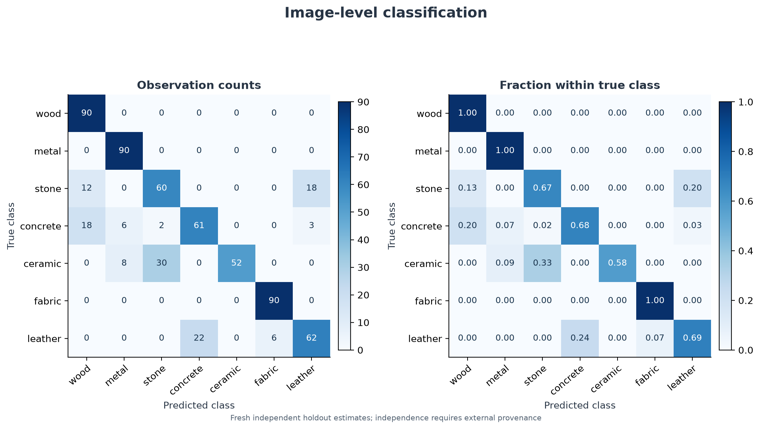

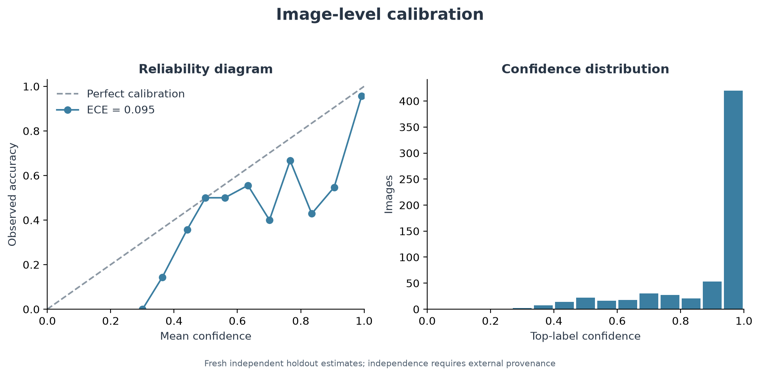

In [9]:
display(Markdown('### ' + labels['frozen_selected']))
saved_plot('fresh/frozen_selected/figures/image_confusion.png', 760)
saved_plot('fresh/frozen_selected/figures/calibration.png', 760)

### Frozen ConvNeXt control

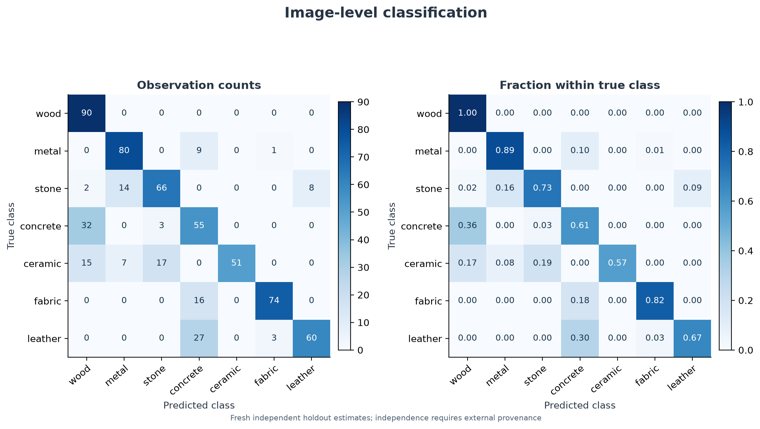

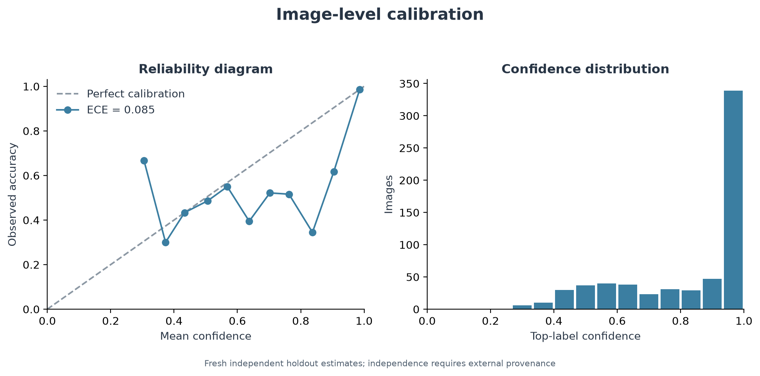

In [10]:
display(Markdown('### ' + labels['frozen_control']))
saved_plot('fresh/frozen_control/figures/image_confusion.png', 760)
saved_plot('fresh/frozen_control/figures/calibration.png', 760)

### ResNet fixed baseline

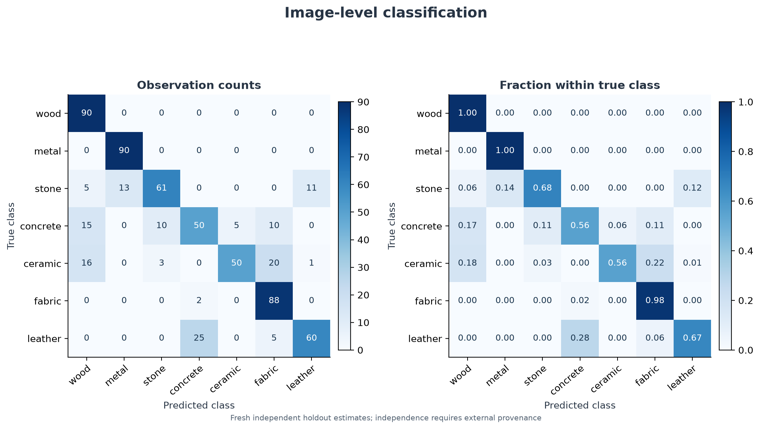

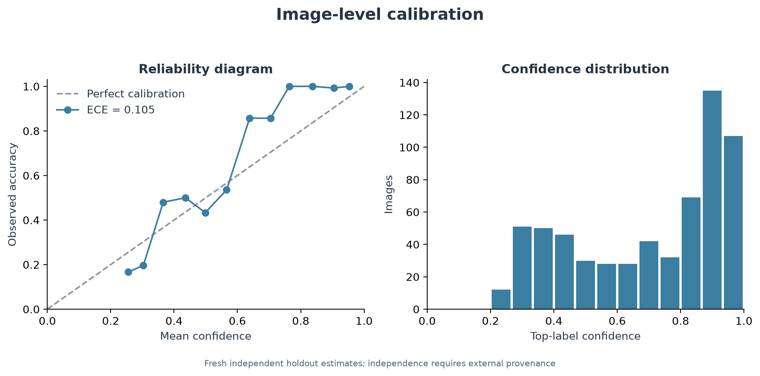

In [11]:
display(Markdown('### ' + labels['resnet_fixed']))
saved_plot('fresh/resnet_fixed/figures/image_confusion.png', 760)
saved_plot('fresh/resnet_fixed/figures/calibration.png', 760)

### DINOv2 fine-tuned (exploratory)

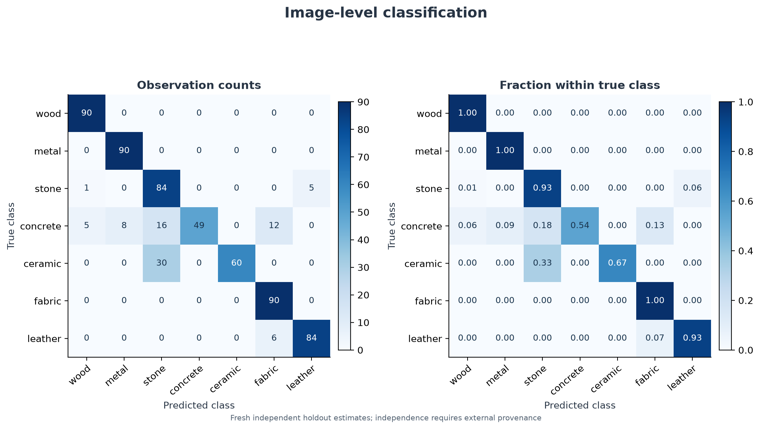

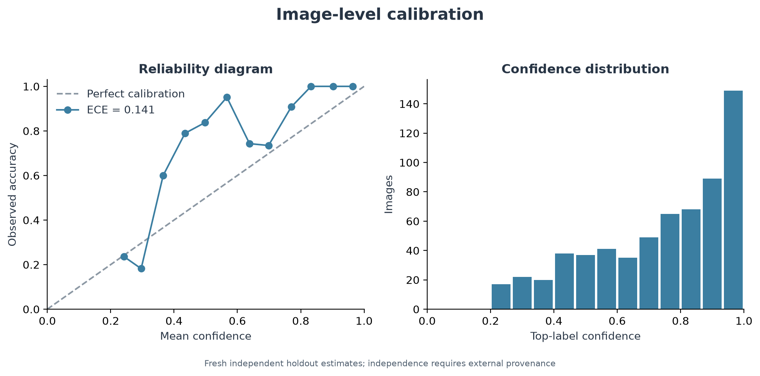

In [12]:
display(Markdown('### ' + labels['dinov2_finetuned']))
saved_plot('fresh/dinov2_finetuned/figures/image_confusion.png', 760)
saved_plot('fresh/dinov2_finetuned/figures/calibration.png', 760)

The primary recalls all fresh wood, metal and fabric views, but only 57.78% of
ceramic views; ceramic â†’ stone accounts for 30 errors. With only three sources
per class, these class results can be dominated by individual texture families.
DINO's higher accuracy does not imply better calibration: inspect its ECE
alongside loss and Brier rather than treating accuracy as probability quality.

## Actual recorded training histories

ResNet has five ten-epoch fold fits plus a ten-epoch all-development fit.
Its histories record training loss/accuracy; outer assessments occur only
after training, so there is no fabricated per-epoch outer-validation curve.
DINO plots include all six development fits and the final five-epoch fit.
Dashed DINO curves are development validation reused for checkpoint selection.
The gap between near-perfect training and lower validation is consistent with
overfitting to the available synthetic families. Final fits have no validation.

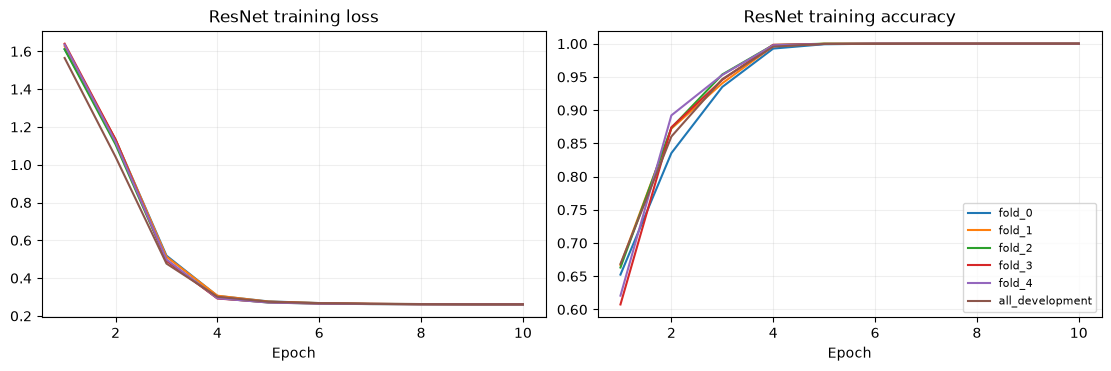

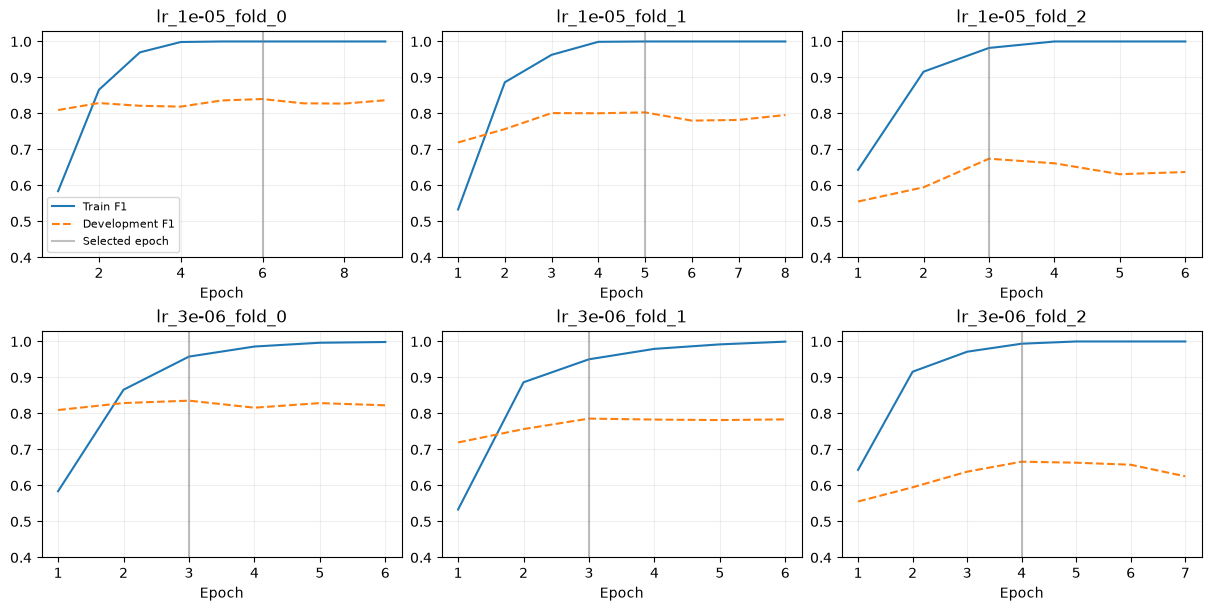

,epoch,head_only,train.loss,train.accuracy,train.macro_f1,train.optimizer_steps,train.amp_skipped_steps,seconds
0,1,True,1.1910,0.6816,0.6817,99,0,41.7157
1,2,True,0.6037,0.9244,0.9248,99,0,43.2535
2,3,False,0.3838,0.9810,0.9810,99,0,43.4352
3,4,False,0.3002,0.9994,0.9994,99,0,46.2430
4,5,False,0.2794,0.9997,0.9997,99,0,59.1705


,model,fit,epochs,epoch seconds
0,ResNet,fold_0,10,395.6151
1,ResNet,fold_1,10,440.2557
2,ResNet,fold_2,10,444.7568
3,ResNet,fold_3,10,379.1879
4,ResNet,fold_4,10,401.1625
5,ResNet,all_development,10,512.0966
6,DINO,lr_1e-05_fold_0,9,635.9218
7,DINO,lr_1e-05_fold_1,8,520.7014
8,DINO,lr_1e-05_fold_2,6,341.5823
9,DINO,lr_3e-06_fold_0,6,433.3996


In [13]:
resnet_histories = {
    f"fold_{i}": read_csv(f"resnet_baseline/fold_{i}/history.csv") for i in range(5)
}
resnet_histories["all_development"] = read_csv("resnet_baseline/final_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for fit, history in resnet_histories.items():
    assert list(history.epoch) == list(range(1, 11))
    assert history.amp_skipped_updates.sum() == 0
    axes[0].plot(history.epoch, history.train_loss, label=fit)
    axes[1].plot(history.epoch, history.train_accuracy, label=fit)
for ax, title in zip(axes, ["ResNet training loss", "ResNet training accuracy"]):
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=0.2)
axes[1].legend(fontsize=8)
plt.show()
plt.close(fig)

dino_histories = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
for ax, path in zip(
    axes.flat, sorted((ROOT / BASE / "finetune_development").glob("lr_*/progress.json"))
):
    progress = read_json(f"finetune_development/{path.parent.name}/progress.json")
    assert progress["status"] == "complete"
    h = pd.json_normalize(progress["history"])
    dino_histories[path.parent.name] = h
    assert h["train.amp_skipped_steps"].sum() == 0
    ax.plot(h.epoch, h["train.macro_f1"], label="Train F1")
    ax.plot(
        h.epoch, h["validation_development_only.macro_f1"], "--", label="Development F1"
    )
    ax.axvline(progress["best_epoch"], color="grey", alpha=0.5, label="Selected epoch")
    ax.set(title=path.parent.name, xlabel="Epoch", ylim=(0.4, 1.03))
    ax.grid(alpha=0.2)
axes.flat[0].legend(fontsize=8)
plt.show()
plt.close(fig)
dino_final = pd.json_normalize(
    read_json("finetune_development/all_development/progress.json")["history"]
)
assert list(dino_final.epoch) == list(range(1, 6))
assert len(dino_histories) == 6
table(
    dino_final[
        [
            "epoch",
            "head_only",
            "train.loss",
            "train.accuracy",
            "train.macro_f1",
            "train.optimizer_steps",
            "train.amp_skipped_steps",
            "seconds",
        ]
    ]
)
table(
    [
        {"model": "ResNet", "fit": k, "epochs": len(h), "epoch seconds": h.seconds.sum()}
        for k, h in resnet_histories.items()
    ]
    + [
        {"model": "DINO", "fit": k, "epochs": len(h), "epoch seconds": h.seconds.sum()}
        for k, h in {**dino_histories, "all_development": dino_final}.items()
    ]
)

## Fixed corruptions: primary and post hoc DINO comparison

Both use the same five previously staged corruptions and fixed clean checkpoints.
Primary corruption evaluation was specified by the endpoint lock. DINO's
extension was added after observing fresh and primary corruption results.
These are paired descriptive sensitivity results, not new independent holdouts
or an established robustness-superiority test. Negative drops mean improvement.
JPEG quality 30 lowers primary accuracy to **59.05%**, versus **75.40%** for DINO.

,model,condition,accuracy,macro_f1,accuracy_drop_from_clean,correct_to_incorrect,incorrect_to_correct
0,Frozen selected (PRIMARY),brightness_low,0.7825,0.7783,0.0190,14,2
1,Frozen selected (PRIMARY),brightness_high,0.8302,0.8238,-0.0286,11,29
2,Frozen selected (PRIMARY),gaussian_blur,0.7714,0.7642,0.0302,19,0
3,Frozen selected (PRIMARY),jpeg_quality30,0.5905,0.5749,0.2111,137,4
4,Frozen selected (PRIMARY),resolution128,0.7508,0.7500,0.0508,47,15
5,DINOv2 fine-tuned (exploratory),brightness_low,0.8524,0.8465,0.0159,11,1
6,DINOv2 fine-tuned (exploratory),brightness_high,0.8905,0.8871,-0.0222,1,15
7,DINOv2 fine-tuned (exploratory),gaussian_blur,0.8000,0.7903,0.0683,44,1
8,DINOv2 fine-tuned (exploratory),jpeg_quality30,0.7540,0.7496,0.1143,94,22
9,DINOv2 fine-tuned (exploratory),resolution128,0.8317,0.8264,0.0365,47,24


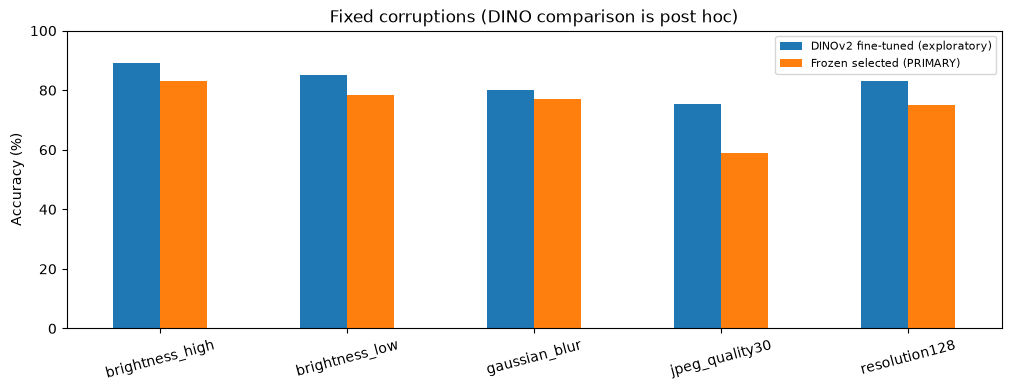

In [14]:
corruptions = []
for directory, name, summary_key in [
    ("primary", "frozen_selected", "robustness"),
    ("dinov2_exploratory", "dinov2_finetuned", "exploratory_robustness"),
]:
    frame = read_csv(f"robustness/{directory}/comparison.csv")
    saved = (
        pd.DataFrame(final[summary_key]["comparison"]).set_index("condition").sort_index()
    )
    actual = frame.set_index("condition").sort_index()
    assert len(frame) == 5 and frame.n_pairs.eq(630).all()
    assert np.allclose(actual[["accuracy", "macro_f1"]], saved[["accuracy", "macro_f1"]])
    assert np.allclose(
        frame.clean_accuracy, evaluations[name]["image_level"]["metrics"]["accuracy"]
    )
    assert np.allclose(
        frame.clean_accuracy - frame.accuracy, frame.accuracy_drop_from_clean
    )
    frame["model"] = labels[name]
    corruptions.append(frame)
corruption_table = pd.concat(corruptions, ignore_index=True)
table(
    corruption_table[
        [
            "model",
            "condition",
            "accuracy",
            "macro_f1",
            "accuracy_drop_from_clean",
            "correct_to_incorrect",
            "incorrect_to_correct",
        ]
    ]
)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
corruption_table.pivot(index="condition", columns="model", values="accuracy").mul(
    100
).plot.bar(ax=ax)
ax.set(
    ylabel="Accuracy (%)",
    xlabel="",
    ylim=(0, 100),
    title="Fixed corruptions (DINO comparison is post hoc)",
)
ax.tick_params(axis="x", rotation=15)
ax.legend(fontsize=8)
plt.show()
plt.close(fig)

## Measured efficiency and deployment footprint

Saved GPU benchmarks use an RTX 4070 Laptop GPU, four requested CPU threads,
five warmups and 30 repetitions, at batch sizes 1 and 16. Warm timings include
preprocessing, transfers, networks and probability output, but exclude file
reading/decoding and model loading. The separate three-trial reload measurement
is **process-warm**, not OS-cold startup. CUDA allocator peaks are not total
board usage. These measurements are hardware- and scope-specific.

Frozen selected's small scaler/head is not a standalone classifier: it needs
two unique pretrained files, with DINO instantiated at two resolutions.
Count that shared stored file once, while retaining separate runtime instances.
Total deployment bytes include saved sidecar metadata. DINO's fine-tuned loader
does not need the original pretrained cache. No FLOPs or CPU-RSS result is claimed.

In [15]:
benchmark_rows, footprint_rows = [], []
for name in names:
    b = read_json(f"benchmarks/{name}/benchmark.json")
    recorded_hash(
        BASE + f"benchmarks/{name}/benchmark.json",
        final["benchmarks"][name]["benchmark_json_sha256"],
    )
    assert b["class_order"] == classes and b["status"] == "complete"
    assert (
        b["deployment"]["artifact"]["sha256"] == lock["models"][name]["artifact_sha256"]
    )
    assert b["settings"]["repetitions"] == 30 and b["settings"]["warmup"] == 5
    for r in b["results"]:
        benchmark_rows.append(
            {
                "model": labels[name],
                "scope": r["scope"],
                "batch": r["batch_size"],
                "median ms/batch": 1000 * r["median_seconds"],
                "p95 ms/batch": 1000 * r["p95_seconds"],
                "images/s": r["images_per_second"],
                "allocated MiB": r["peak_allocated_bytes"] / 2**20,
                "reserved MiB": r["peak_reserved_bytes"] / 2**20,
            }
        )
    d = b["deployment"]
    footprint_rows.append(
        {
            "model": labels[name],
            "artifact MB": d["artifact"]["bytes"] / 1e6,
            "unique pretrained MB": d["unique_pretrained_weight_bytes"] / 1e6,
            "total deployment MB": d["total_deployment_bytes"] / 1e6,
            "dependency": d["dependency_note"],
        }
    )
table(benchmark_rows, 2)
table(footprint_rows, 3)
table(
    [
        {
            "stage": s["label"],
            "wall seconds": s["duration_seconds"],
            "status": s["status"],
        }
        for s in neural["stages"]
    ],
    2,
)
extraction = read_json("extraction_summary.json")
print(
    "Initial feature extraction session seconds:",
    round(sum(j["session_seconds"] for j in extraction["jobs"].values()), 2),
)
print("Initial frozen nested/head run seconds:", round(frozen_run["seconds"], 2))
print(
    "Initial timings exclude later guard revalidation; "
    "neural wall times include stage overhead."
)

,model,scope,batch,median ms/batch,p95 ms/batch,images/s,allocated MiB,reserved MiB
0,Frozen selected (PRIMARY),process_warm_reload,1,1558.72,2311.78,0.56,319.01,344.0
1,Frozen selected (PRIMARY),warm,1,42.88,50.62,24.24,319.01,342.0
2,Frozen selected (PRIMARY),warm,16,344.58,373.42,46.36,521.31,900.0
3,Frozen ConvNeXt control,process_warm_reload,1,452.53,1577.76,1.17,155.77,164.0
4,Frozen ConvNeXt control,warm,1,14.20,18.35,65.95,155.77,164.0
5,Frozen ConvNeXt control,warm,16,87.55,107.40,174.42,356.38,590.0
6,ResNet fixed baseline,process_warm_reload,1,431.43,680.87,1.95,150.88,182.0
7,ResNet fixed baseline,warm,1,9.46,10.13,108.24,150.88,182.0
8,ResNet fixed baseline,warm,16,52.35,60.53,294.69,294.40,332.0
9,DINOv2 fine-tuned (exploratory),process_warm_reload,1,369.48,498.79,2.40,127.65,150.0


,model,artifact MB,unique pretrained MB,total deployment MB,dependency
0,Frozen selected (PRIMARY),0.311,202.619,203.630,Pinned cached pretrained safetensors required; jobl...
1,Frozen ConvNeXt control,0.199,114.374,115.272,Pinned cached pretrained safetensors required; jobl...
2,ResNet fixed baseline,94.380,0.000,95.315,Exported .pt contains network state. Current deploy...
3,DINOv2 fine-tuned (exploratory),87.088,0.000,88.027,Exported .pt contains network state. Current deploy...


,stage,wall seconds,status
0,resnet-oof,2262.88,complete
1,resnet-final,576.59,complete
2,dino-select,2955.49,complete
3,dino-final,277.24,complete


Initial feature extraction session seconds: 188.16
Initial frozen nested/head run seconds: 50.12
Initial timings exclude later guard revalidation; neural wall times include stage overhead.


## Limitations and interpretation

- Synthetic-only evidence, a restricted seven-class fresh taxonomy, and just
  three fresh source groups per class limit generalization and CI resolution.
  More camera views cannot substitute for more independent materials/sources.
- Fresh rendering uses a different renderer version; softer shadows and other
  renderer/domain differences are possible. Source novelty and renderer shift
  are not disentangled by this study.
- No backbone-pretraining overlap audit was performed. Novelty relative to
  this project's development corpus does not establish novelty relative to
  pretrained backbone corpora. There is no arbitrary real-world guarantee.
- Historical data, including the old test split, were reused for development.
  Nested OOF evaluates the frozen selection procedure; DINO's chosen best
  development mean is optimistic and must not be presented as outer CV.
- DINO is exploratory; its extra corruption evaluation is post hoc. Fresh
  paired intervals include zero, and no superiority claim or primary switch
  follows from the point ranking. Fixed-prediction intervals omit refitting
  and model-selection uncertainty and depend on the source independence assumption.
- This notebook checks committed evidence and cross-record identities. It does
  not re-audit raw images, rerun training/inference/bootstrap, or remeasure speed.
  Integrity hashes are not a substitute for independent experimental replication.

## Runnable reproduction (saved evidence only)

From the repository root, use Python 3.13 and the existing V3 environment.
Optional notebook packages are isolated in `requirements-notebook.txt`; the ML
lock is unchanged. On Windows replace `.venv/bin/python` with
`.venv/Scripts/python.exe`:

```sh
.venv/bin/python -m pip install -c requirements-v3-lock.txt -r requirements-notebook.txt
.venv/bin/python scripts/v3/build_results_notebook.py --execute
```

The builder uses **nbclient** and a temporary task-local kernelspec pointing
at that interpreter; it installs no global kernel. Without `--execute` it
builds an unexecuted notebook. To keep this committed snapshot intact, choose
a separate `--output` path. The notebook can also be run top-to-bottom in an
existing Python kernel from the root or `notebooks/` directory. No raw dataset,
model checkpoint, GPU, or network is needed after dependencies are installed.

The embedded inventory pins the saved snapshot. Rebuilding intentionally
refreshes those pins from `--root`; executing the committed notebook directly
verifies the existing pins. Review changed evidence before accepting new pins.
Full training/scoring command records remain in `neural_execution_summary.json`
and `final_execution_summary.json`; they are not executed here.

To independently regenerate metrics and plots from the **saved** primary
predictions (optional, not run by this notebook), use a new output directory:

```sh
.venv/bin/python scripts/v3/evaluate.py \
  --predictions reports/results/v3/fresh/frozen_selected/predictions.csv \
  --metadata reports/results/v3/final_model_lock.json \
  --output-dir artifacts/v3/notebook_recheck_primary \
  --estimate-type fresh_holdout --label-format indices \
  --n-bootstrap 10000 --seed 62642 --n-bins 15
```

This evaluator reads prediction CSVs, not images or checkpoints. The saved
evaluator seed is 62642 for this endpoint. Do not install the historical
`.[dev]` extras into the validated V3 environment: their older scikit-learn and
ipykernel pins differ from the V3 lock and these optional notebook pins.
The multiline example uses shell backslash continuations; in PowerShell,
join those lines into one command and use `.venv/Scripts/python.exe`.

In [16]:
assert len(evaluations) == 4 and len(resnet_histories) == 6 and len(dino_histories) == 6
print("PASS: pinned evidence hashes; lock/choice chronology; source-group counts;")
print("four saved prediction identities and metrics; paired intervals; actual histories;")
print(
    "corruption consistency; benchmark/checkpoint identity. No training or scoring performed."
)
print("Evidence files verified:", len(EXPECTED_SHA256))

PASS: pinned evidence hashes; lock/choice chronology; source-group counts;
four saved prediction identities and metrics; paired intervals; actual histories;
corruption consistency; benchmark/checkpoint identity. No training or scoring performed.
Evidence files verified: 61
